<a href="https://colab.research.google.com/github/Solomon-hub23/data-science-project/blob/main/PROJECTS/appliance_energy_prediction/Notebook/Appliance_Energy_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as pyplot
import seaborn as sns

In [ ]:
df=pd.read_csv("../Dataset/energydata_complete.csv")
df_original=df.copy()

In [ ]:
df.shape

(19735, 29)

In [ ]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
df.head().T

,0,1,2,3,4
date,2016-01-11 17:00:00,2016-01-11 17:10:00,2016-01-11 17:20:00,2016-01-11 17:30:00,2016-01-11 17:40:00
Appliances,60,60,50,50,60
lights,30,30,30,40,40
T1,19.89,19.89,19.89,19.89,19.89
RH_1,47.596667,46.693333,46.3,46.066667,46.333333
T2,19.2,19.2,19.2,19.2,19.2
RH_2,44.79,44.7225,44.626667,44.59,44.53
T3,19.79,19.79,19.79,19.79,19.79
RH_3,44.73,44.79,44.933333,45.0,45.0
T4,19.0,19.0,18.926667,18.89,18.89


In [ ]:
df.tail()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
19730,2016-05-27 17:20:00,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.7,...,23.2,46.7900,22.733333,755.2,55.666667,3.333333,23.666667,13.333333,43.096812,43.096812
19731,2016-05-27 17:30:00,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.7,...,23.2,46.7900,22.600000,755.2,56.000000,3.500000,24.500000,13.300000,49.282940,49.282940
19732,2016-05-27 17:40:00,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.7,...,23.2,46.7900,22.466667,755.2,56.333333,3.666667,25.333333,13.266667,29.199117,29.199117
19733,2016-05-27 17:50:00,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.7,...,23.2,46.8175,22.333333,755.2,56.666667,3.833333,26.166667,13.233333,6.322784,6.322784
19734,2016-05-27 18:00:00,430,10,25.500000,46.600000,25.264286,42.971429,26.823333,41.156667,24.7,...,23.2,46.8450,22.200000,755.2,57.000000,4.000000,27.000000,13.200000,34.118851,34.118851


In [ ]:
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [ ]:
df.dtypes

date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object

In [ ]:
missing=df.isnull().sum()
missing_percentage=(missing/len(df)*100)

pd.DataFrame({'Missing_Count':missing,"Missing_%":missing_percentage}).sort_values('Missing_%', ascending=False)

,Missing_Count,Missing_%
date,0,0.0
Appliances,0,0.0
lights,0,0.0
T1,0,0.0
RH_1,0,0.0
T2,0,0.0
RH_2,0,0.0
T3,0,0.0
RH_3,0,0.0
T4,0,0.0


In [ ]:
duplicates=df.duplicated().sum()
duplicates

np.int64(0)

In [ ]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique")

date: 19735 unique
Appliances: 92 unique
lights: 8 unique
T1: 722 unique
RH_1: 2547 unique
T2: 1650 unique
RH_2: 3376 unique
T3: 1426 unique
RH_3: 2618 unique
T4: 1390 unique
RH_4: 2987 unique
T5: 2263 unique
RH_5: 7571 unique
T6: 4446 unique
RH_6: 9709 unique
T7: 1955 unique
RH_7: 5891 unique
T8: 2228 unique
RH_8: 6649 unique
T9: 924 unique
RH_9: 3388 unique
T_out: 1730 unique
Press_mm_hg: 2189 unique
RH_out: 566 unique
Windspeed: 189 unique
Visibility: 413 unique
Tdewpoint: 1409 unique
rv1: 19735 unique
rv2: 19735 unique


In [ ]:
df.rv1

0        13.275433
1        18.606195
2        28.642668
3        45.410389
4        10.084097
           ...    
19730    43.096812
19731    49.282940
19732    29.199117
19733     6.322784
19734    34.118851
Name: rv1, Length: 19735, dtype: float64

In [ ]:
#checking if col rv1 and rv2 are the same
df['rv1'].equals(df['rv2'])

True

#### Since col `rv1` and `rv2` are the same, we would delete rv2

In [ ]:
df=df.drop('rv2', axis=1)

In [ ]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1'],
      dtype='str')

In [ ]:
#lets convert the date column to datetime format
df['date']=pd.to_datetime(df['date'])
df.set_index('date', inplace=True)
df


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60,30,19.890000,47.596667,19.200000,44.790000,19.790000,44.730000,19.000000,45.566667,...,48.900000,17.033333,45.5300,6.600000,733.5,92.000000,7.000000,63.000000,5.300000,13.275433
2016-01-11 17:10:00,60,30,19.890000,46.693333,19.200000,44.722500,19.790000,44.790000,19.000000,45.992500,...,48.863333,17.066667,45.5600,6.483333,733.6,92.000000,6.666667,59.166667,5.200000,18.606195
2016-01-11 17:20:00,50,30,19.890000,46.300000,19.200000,44.626667,19.790000,44.933333,18.926667,45.890000,...,48.730000,17.000000,45.5000,6.366667,733.7,92.000000,6.333333,55.333333,5.100000,28.642668
2016-01-11 17:30:00,50,40,19.890000,46.066667,19.200000,44.590000,19.790000,45.000000,18.890000,45.723333,...,48.590000,17.000000,45.4000,6.250000,733.8,92.000000,6.000000,51.500000,5.000000,45.410389
2016-01-11 17:40:00,60,40,19.890000,46.333333,19.200000,44.530000,19.790000,45.000000,18.890000,45.530000,...,48.590000,17.000000,45.4000,6.133333,733.9,92.000000,5.666667,47.666667,4.900000,10.084097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-05-27 17:20:00,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.700000,45.590000,...,50.074000,23.200000,46.7900,22.733333,755.2,55.666667,3.333333,23.666667,13.333333,43.096812
2016-05-27 17:30:00,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.700000,45.590000,...,49.790000,23.200000,46.7900,22.600000,755.2,56.000000,3.500000,24.500000,13.300000,49.282940
2016-05-27 17:40:00,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.700000,45.730000,...,49.660000,23.200000,46.7900,22.466667,755.2,56.333333,3.666667,25.333333,13.266667,29.199117


In [ ]:
#creating a new column for hour, day, month, and year to check for enerhgy consumption patterns
df['hour']=df.index.hour
df['day']=df.index.day
df['month']=df.index.month
df['year']=df.index.year


### EDA- Exploratory Data Analysis

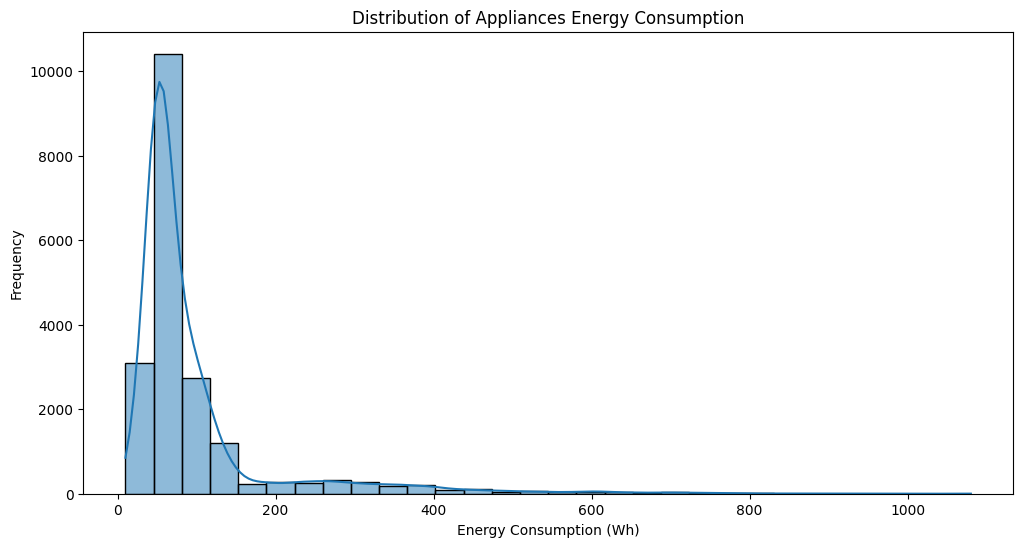

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.histplot(df['Appliances'], bins=30, kde=True)
plt.title('Distribution of Appliances Energy Consumption')
plt.xlabel('Energy Consumption (Wh)')
plt.ylabel('Frequency')
plt.show()

<Axes: >

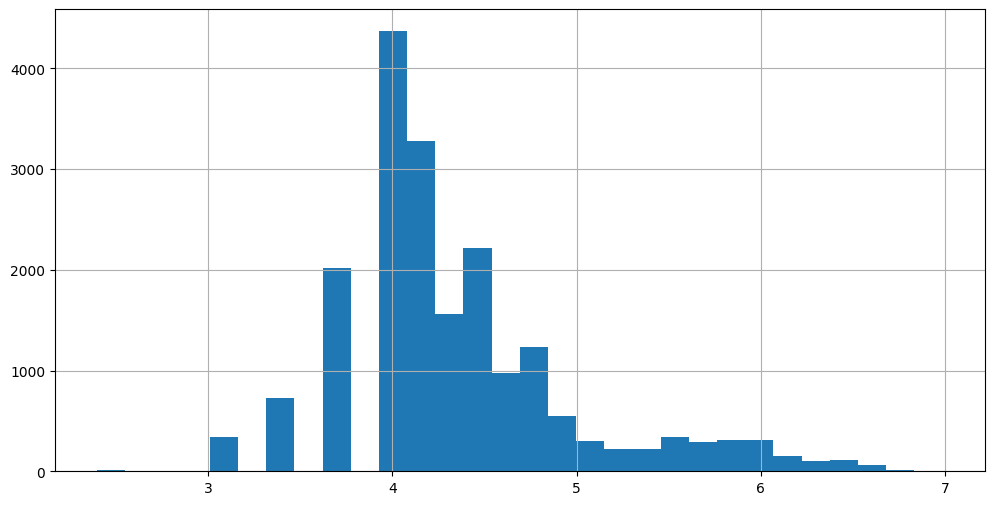

In [ ]:
#log scaling the target variable (appliance) to reduce skewness
df['Appliances_log'] = np.log1p(df['Appliances'])
df['Appliances_log'].hist(bins=30, figsize=(12,6))

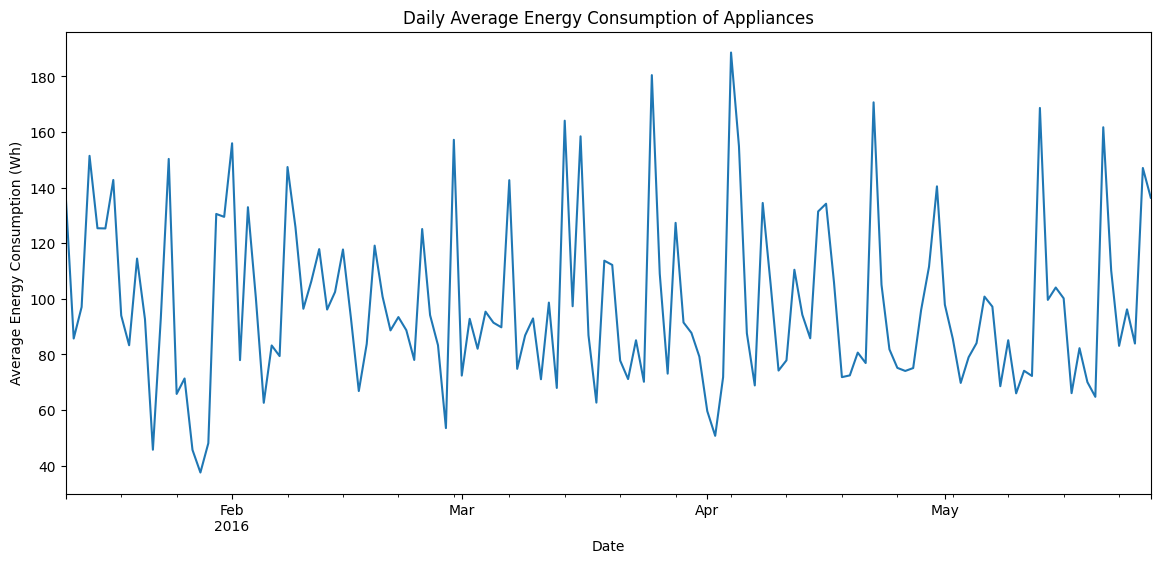

In [ ]:
#checking if specific days have higher energy consumption than others
df['Appliances'].resample('D').mean().plot(figsize=(14,6))
plt.title('Daily Average Energy Consumption of Appliances')
plt.xlabel('Date')
plt.ylabel('Average Energy Consumption (Wh)')
plt.show()

#### The daily average appliance energy consumption is higly volatile, ranging from approximately 40Wh to 170 Wh, with typicl value around 90 Wh. No clear season, trend is observed between January and May. The flunctuations indicate that daily usage is driven by occupant activities, with notable peaks in early February and  mid-April

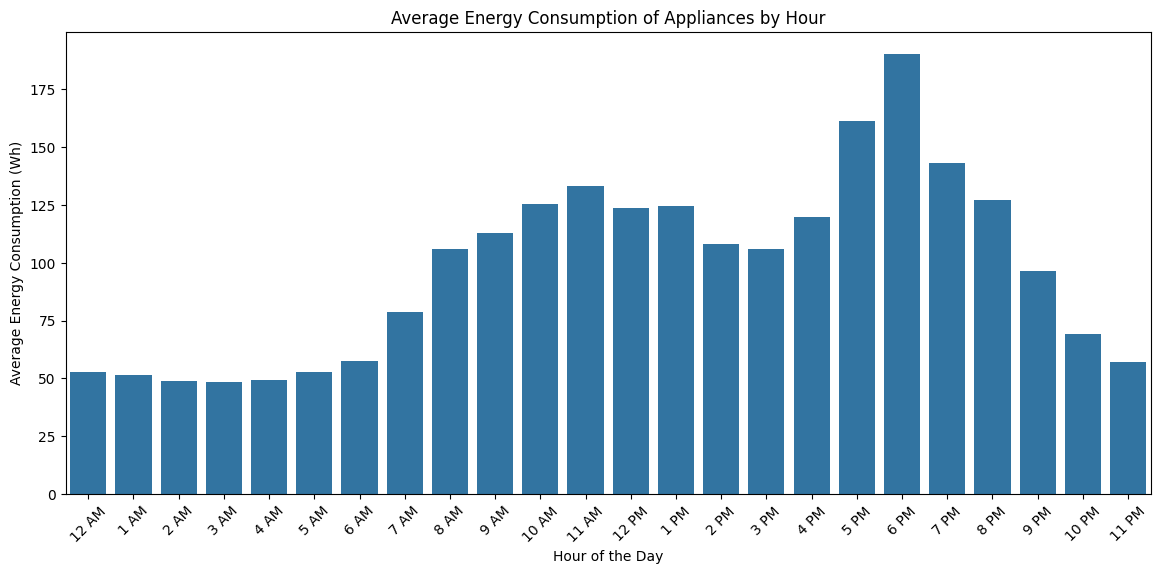

In [ ]:
#checking if specific hours have higher energy consumption than others

plt.figure(figsize=(14,6))
sns.barplot(x=df['hour'], y=df['Appliances'], errorbar=None)
plt.title("Average Energy Consumption of Appliances by Hour")
plt.xticks(ticks=range(24), labels=[f"{h%12 or 12} {'AM' if h < 12 else 'PM'}" for h in range(24)], rotation=45)
plt.xlabel("Hour of the Day")
plt.ylabel("Average Energy Consumption (Wh)")
plt.show()

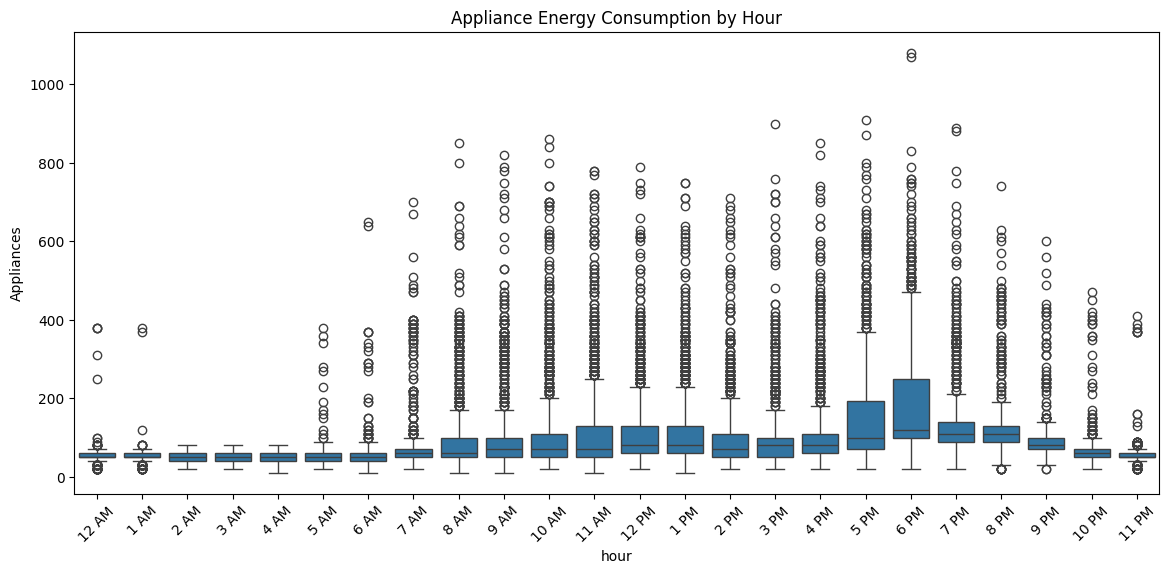

In [ ]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x='hour', y='Appliances')
plt.xticks(ticks=range(24), labels=[f"{h%12 or 12} {'AM' if h < 12 else 'PM'}" for h in range(24)], rotation=45)
plt.title('Appliance Energy Consumption by Hour')
plt.show()

Text(0.5, 1.0, 'Appliance Energy Consumption vs Temperature Sensors')

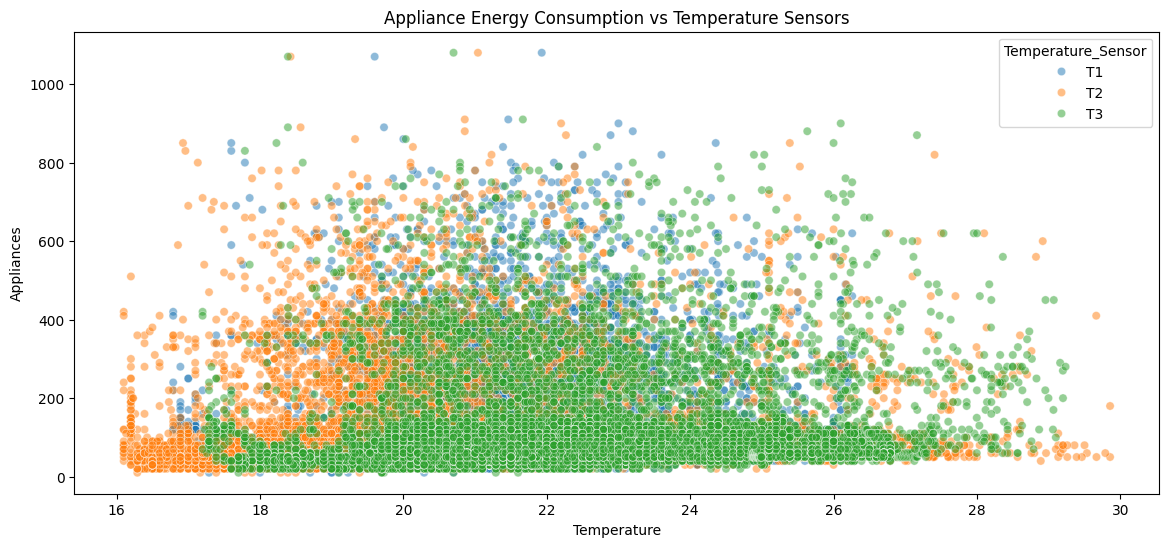

In [ ]:
#scatter diagram of 3 temperatures vs appliance energy consumption
plt.figure(figsize=(14,6))
#melt T1, T2, T3 into a long format for easier plotting
temp_df = df.melt(id_vars=['Appliances'], value_vars=['T1', 'T2', 'T3'], var_name='Temperature_Sensor', value_name='Temperature')
sns.scatterplot(data=temp_df, x='Temperature', y='Appliances', hue='Temperature_Sensor', alpha=0.5)
plt.title('Appliance Energy Consumption vs Temperature Sensors')


Text(0.5, 1.0, 'Appliance Energy Consumption vs Windspeed')

<Figure size 1400x600 with 0 Axes>

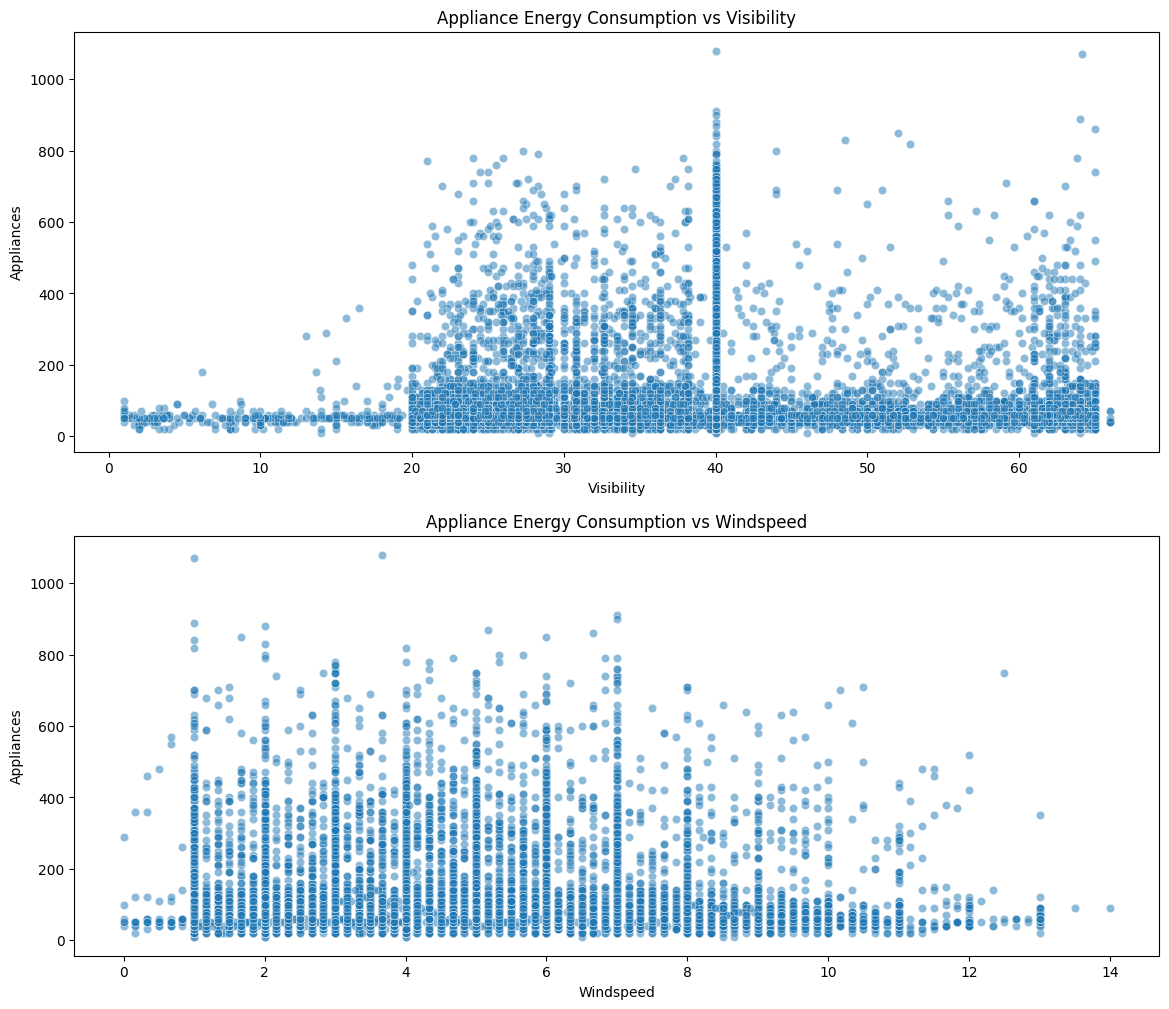

In [ ]:
plt.figure(figsize=(14,6))
fig, ax=plt.subplots(2,1, figsize=(14,12))
sns.scatterplot(data=df, x='Visibility', y='Appliances', ax=ax[0], alpha=0.5).set_title('Appliance Energy Consumption vs Visibility')
sns.scatterplot(data=df, x='Windspeed', y='Appliances', ax=ax[1], alpha=0.5).set_title('Appliance Energy Consumption vs Windspeed')

#### The other temperature sensors show similar distribution

<Axes: >

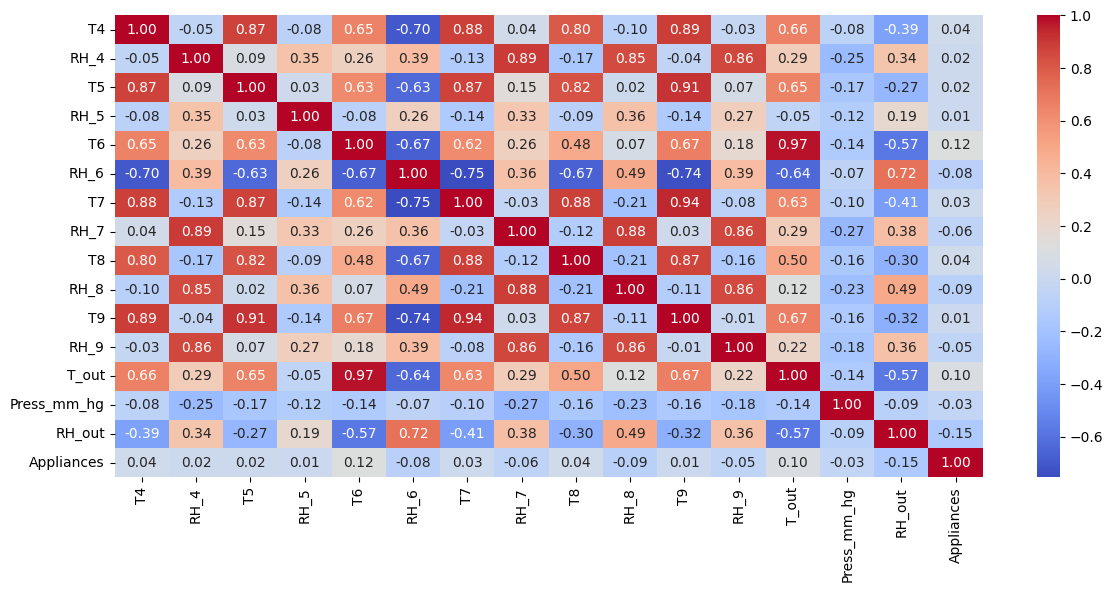

In [ ]:
plt.figure(figsize=(14,6))
columns=[ 'T4','RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9','RH_9', 'T_out', 'Press_mm_hg', 'RH_out','Appliances']
sns.heatmap(df[columns].corr(numeric_only=True), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)


Text(0.5, 1.0, 'Feature Correlation Heatmap')

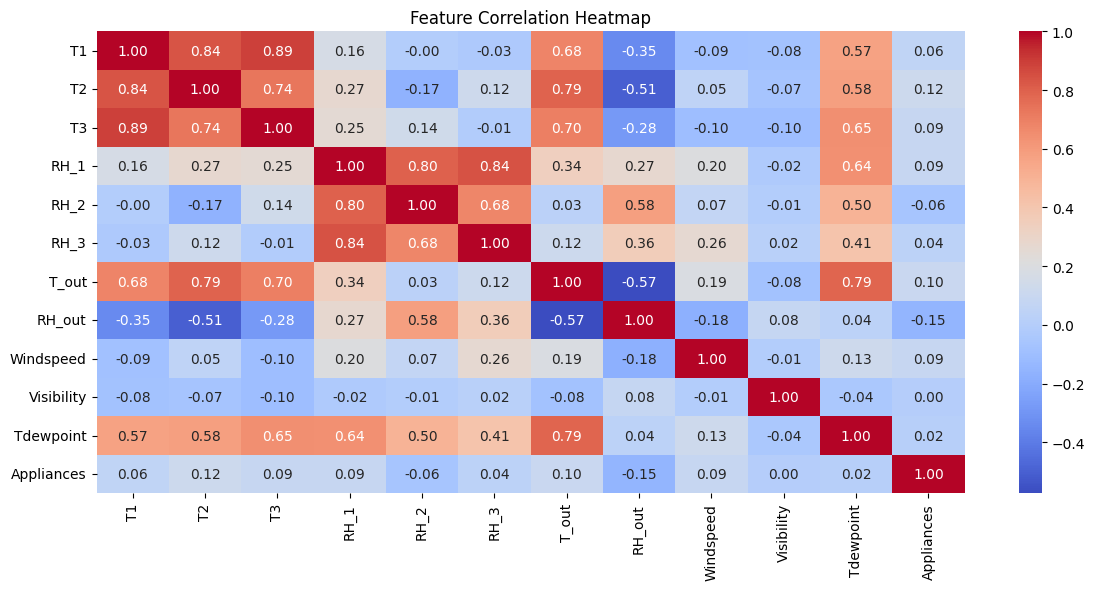

In [ ]:
plt.figure(figsize=(14,6))
cols=['T1', 'T2', 'T3', 'RH_1', 'RH_2', 'RH_3', 'T_out', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint','Appliances']
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Feature Correlation Heatmap')


### Models

#### Building our baseline model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold


X=df.drop(['Appliances', 'Appliances_log'], axis=1)
y=df['Appliances_log']

#Calculating the indices for splitting the dataset into training, validation, and test sets
train_index=int(len(df)*0.70)
val_index=int(len(df)*0.85)

#training dataset (70% of the data)
X_train=X.iloc[:train_index]
y_train=y.iloc[:train_index]

#validation dataset (15% of the data)
X_val=X.iloc[train_index:val_index]
y_val=y.iloc[train_index:val_index]

#test dataset (15% of the data)
X_test=X.iloc[val_index:]
y_test=y.iloc[val_index:]


In [ ]:

pipe_linear=Pipeline([
    ('scaler', RobustScaler()),
    ('model', LinearRegression())
])
pipe_svr=Pipeline([
    ('scaler', RobustScaler()),
    ('model', SVR())
])
pipe_knn=Pipeline([
    ('scaler', RobustScaler()),
    ('model', KNeighborsRegressor())
])
models={
    'Linear Regression': pipe_linear,
    'Support Vector Regression': pipe_svr,
    'K-Nearest Neighbors': pipe_knn
}
tscp=TimeSeriesSplit(n_splits=5)

scores=[]
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred_val=model.predict(X_val)
    rmse_val=np.sqrt(mean_squared_error(y_val, y_pred_val))
    cross=cross_val_score(model,X_train,y_train, cv=tscp, scoring='r2')
    mae=mean_absolute_error(y_val, y_pred_val)
    r2_val=r2_score(y_val, y_pred_val)
    scores.append(
    {
        'Model': model_name,
        'Validation RMSE': rmse_val,
        'Validation R2': r2_val,
        'Validation MAE': mae,
        'cross_mean': cross.mean(),
        'cross_std': cross.std()
    }
    )

result=pd.DataFrame(scores).sort_values('Validation RMSE', ascending=True).set_index('Model')
print(result)

                           Validation RMSE  Validation R2  Validation MAE  \
Model                                                                       
Linear Regression                 0.510297       0.215121        0.367547   
Support Vector Regression         0.563788       0.041950        0.401319   
K-Nearest Neighbors               0.621360      -0.163705        0.428488   

                           cross_mean  cross_std  
Model                                             
Linear Regression           -0.051584   0.336177  
Support Vector Regression    0.020785   0.205997  
K-Nearest Neighbors         -0.180607   0.199046  


### More Added improved features

In [ ]:
#Temporal features
df['day_of_week']=df.index.dayofweek
df['is_weekend']=(df['day_of_week']>=5).astype(int)

#cyclical hour feature
df['hour_sin']=np.sin(2*np.pi*df.index.hour/24)
df['hour_cos']=np.cos(2*np.pi*df.index.hour/24)

indoor_cols=[
  f'T{i}' for i in range(1,10)
  if f'T{i}' in df.columns
]

if 'T_out' in df.columns:
  for col in indoor_cols:
    df[f'delta_{col}_out']=df[col]-df['T_out']

if 'T1' in df.columns and 'T2' in df.columns:
    df['delta_T1_T2']=df['T1']-df['T2']



In [ ]:
X=df.drop(['Appliances', 'Appliances_log'], axis=1)
y=df['Appliances_log']

#Calculating the indices for splitting the dataset into training, validation, and test sets
train_index=int(len(df)*0.70)
val_index=int(len(df)*0.85)

#training dataset (70% of the data)
X_train=X.iloc[:train_index]
y_train=y.iloc[:train_index]

#validation dataset (15% of the data)
X_val=X.iloc[train_index:val_index]
y_val=y.iloc[train_index:val_index]

#test dataset (15% of the data)
X_test=X.iloc[val_index:]
y_test=y.iloc[val_index:]


Pipe_linear=Pipeline([
    ('scaler', RobustScaler()),
    ('model', LinearRegression())
])
pipe_svr=Pipeline([
    ('scaler', RobustScaler()),
    ('model', SVR())
])
pipe_knn=Pipeline([
    ('scaler', RobustScaler()),
    ('model', KNeighborsRegressor())
])

models={
    'Linear Regression': pipe_linear,
    'Support Vector Regression': pipe_svr,
    'K-Nearest Neighbors': pipe_knn
}
tscp=TimeSeriesSplit(n_splits=5)
scores=[]
for model_name, model in models.items():
    cross=cross_val_score(model,X_train,y_train, cv=tscp)
    model.fit(X_train,y_train)
    y_pred=model.predict(X_val)
    rmse_val=np.sqrt(mean_squared_error(y_val, y_pred))
    mae=mean_absolute_error(y_val, y_pred)
    r2_val=r2_score(y_val, y_pred)
    scores.append(
    {
        'Model': model_name,
        'Validation RMSE': rmse_val,
        'Validation R2': r2_val,
        'Validation MAE': mae,
        'cross_val_score': cross.mean()
    }
    )
print(pd.DataFrame(scores))

                       Model  Validation RMSE  Validation R2  Validation MAE  \
0          Linear Regression         0.529470       0.155033        0.387052   
1  Support Vector Regression         0.579929      -0.013693        0.401168   
2        K-Nearest Neighbors         0.562513       0.046278        0.392448   

   cross_val_score  
0         0.190640  
1         0.132874  
2        -0.137738  


### Feature Engineering and Experimental Evaluation

Following the baseline modelling stage, additional features were engineered to investigate whether temporal patterns and thermal relationships could improve the prediction of appliance energy consumption.

The feature-engineering process focused on two main areas:

**1. Temporal and Cyclical Features**

The day of the week and a weekend indicator were introduced to capture potential differences in household energy consumption between weekdays and weekends. Additionally, cyclical hour encoding using sine and cosine transformations was applied to represent the circular nature of time, ensuring that hours close to midnight were treated as temporally related.

**2. Thermal Differential Features**

Temperature difference features were created by calculating the difference between each available indoor temperature measurement (T1–T9) and the outdoor temperature (T_out). A further feature, delta_T1_T2, was introduced to capture the temperature difference between two indoor measurement locations.

These transformations were intended to help the models identify relationships between indoor and outdoor thermal conditions that might be associated with appliance energy consumption.

**Experimental Evaluation**

The engineered features were evaluated against the original baseline feature set using the same chronological validation split and evaluation metrics.

The results showed that the additional features affected the algorithms differently. Linear Regression experienced a decline in R² from 0.2151 to 0.1550, whereas SVR improved from 0.0420 to 0.0855 and KNN improved from -0.1637 to -0.0444.

Despite the improvements recorded by SVR and KNN, their overall predictive performance remained below that of the original Linear Regression baseline.

These findings indicate that the usefulness of engineered features is model-dependent. Consequently, the additional features will be evaluated individually and in combination with the original features during subsequent model comparisons. Their inclusion in the final modelling pipeline will be determined by validation performance on two differnt features (original and new) rather than the assumption that additional features necessarily improve prediction accuracy.

In [ ]:
original_features=['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'rv1', 'hour', 'day', 'month', 'year', 'Appliances_log']

new_features=['day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'delta_T1_T2'] + original_features


### Testing different models with both new and old features

In [ ]:
X=df[original_features].drop(['Appliances', 'Appliances_log'], axis=1)
y=df['Appliances_log']

train_index=int(len(df)*0.70)
validation_index=int(len(df)*0.85)

X_train=X.iloc[:train_index]
y_train=y.iloc[:train_index]

X_val=X.iloc[train_index:validation_index]
y_val=y.iloc[train_index:validation_index]

X_test=X.iloc[validation_index:]
y_test=y.iloc[validation_index:]


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor

models={
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor(),
    'Extra Trees': ExtraTreesRegressor(),
    'Gradient Boosting': GradientBoostingRegressor()
}
tscv=TimeSeriesSplit(n_splits=5)
scores=[]
for model_name, model in models.items():
    model.fit(X_train,y_train)
    y_pred=model.predict(X_val)
    r2=r2_score(y_val, y_pred)
    mean_ab_error=mean_absolute_error(y_val, y_pred)
    root_mean_sqr_error=np.sqrt(mean_squared_error(y_val, y_pred))
    cross_val_results =cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
    scores.append(
    {
        'Model': model_name,
        'Mean R2': np.mean(cross_val_results),
        'Std R2': np.std(cross_val_results),
        'R2': r2,
        'MAE': mean_ab_error,
        'RMSE': root_mean_sqr_error
    }
    )

print(pd.DataFrame(scores).sort_values('Mean R2', ascending=False).set_index('Model'))


                    Mean R2    Std R2        R2       MAE      RMSE
Model                                                              
Extra Trees        0.223811  0.064415  0.232997  0.357104  0.504453
Gradient Boosting  0.176680  0.134158  0.189495  0.374277  0.518561
Random Forest      0.071637  0.078482  0.134148  0.397635  0.535974
Decision Tree     -0.866199  0.458187 -0.879319  0.562002  0.789627


In [ ]:
X=df[new_features].drop(['Appliances', 'Appliances_log'], axis=1)
y=df['Appliances_log']

train_index=int(len(df)*0.70)
validation_index=int(len(df)*0.85)

X_train=X.iloc[:train_index]
y_train=y.iloc[:train_index]

X_val=X.iloc[train_index:validation_index]
y_val=y.iloc[train_index:validation_index]

X_test=X.iloc[validation_index:]
y_test=y.iloc[validation_index:]


In [ ]:
models={
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor(),
    'Extra Trees': ExtraTreesRegressor(),
    'Gradient Boosting': GradientBoostingRegressor()
}

tscv=TimeSeriesSplit(n_splits=5)

scores=[]
for model_name, model in models.items():
    cross_val_results =cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
    model.fit(X_train,y_train)
    y_pred=model.predict(X_val)
    r2=r2_score(y_val, y_pred)
    mean_ab_error=mean_absolute_error(y_val, y_pred)
    root_mean_sqr_error=np.sqrt(mean_squared_error(y_val, y_pred))
    scores.append(
    {
        'Model': model_name,
        'Mean R2': np.mean(cross_val_results),
        'Std R2': np.std(cross_val_results),
        'R2': r2,
        'MAE': mean_ab_error,
        'RMSE': root_mean_sqr_error

    }
    )

print(pd.DataFrame(scores).sort_values('Mean R2', ascending=False).set_index('Model'))

                    Mean R2    Std R2        R2       MAE      RMSE
Model                                                              
Extra Trees        0.236882  0.051183  0.251971  0.355703  0.498174
Gradient Boosting  0.201942  0.105506  0.252748  0.350289  0.497915
Random Forest      0.117983  0.087842  0.102944  0.408058  0.545546
Decision Tree     -0.891390  0.437704 -0.978506  0.575231  0.810197


### lets us test with more advanced models

In [ ]:
from catboost import CatBoostRegressor

cat_model=CatBoostRegressor()
X=df[new_features].drop(['Appliances', 'Appliances_log'], axis=1)
y=df['Appliances_log']

train_index=int(len(df)*0.70)
validation_index=int(len(df)*0.85)

X_train=X.iloc[:train_index]
y_train=y.iloc[:train_index]

X_val=X.iloc[train_index:validation_index]
y_val=y.iloc[train_index:validation_index]

X_test=X.iloc[validation_index:]
y_test=y.iloc[validation_index:]


cat_model.fit(X_train,y_train)
print(cat_model.score(X_val,y_val))
tsp=TimeSeriesSplit(n_splits=7)
cross=cross_val_score(cat_model, X_train,y_train, cv=tsp)
print(cross.mean())
print(cross.std())

Learning rate set to 0.061994
0:	learn: 0.6675262	total: 1.59s	remaining: 26m 33s
1:	learn: 0.6546357	total: 1.67s	remaining: 13m 53s
2:	learn: 0.6429498	total: 1.72s	remaining: 9m 32s
3:	learn: 0.6321631	total: 1.77s	remaining: 7m 20s
4:	learn: 0.6231914	total: 1.82s	remaining: 6m 1s
5:	learn: 0.6145844	total: 1.86s	remaining: 5m 8s
6:	learn: 0.6068581	total: 1.91s	remaining: 4m 30s
7:	learn: 0.5995767	total: 1.95s	remaining: 4m 1s
8:	learn: 0.5923528	total: 2s	remaining: 3m 40s
9:	learn: 0.5863744	total: 2.04s	remaining: 3m 22s
10:	learn: 0.5805811	total: 2.09s	remaining: 3m 7s
11:	learn: 0.5758812	total: 2.13s	remaining: 2m 55s
12:	learn: 0.5712630	total: 2.27s	remaining: 2m 52s
13:	learn: 0.5670317	total: 2.32s	remaining: 2m 43s
14:	learn: 0.5626840	total: 2.36s	remaining: 2m 35s
15:	learn: 0.5592044	total: 2.41s	remaining: 2m 28s
16:	learn: 0.5555967	total: 2.46s	remaining: 2m 21s
17:	learn: 0.5520844	total: 2.51s	remaining: 2m 16s
18:	learn: 0.5492238	total: 2.55s	remaining: 2m 1

In [ ]:
y_pred=cat_model.predict(X_val)
actual=np.expm1(y_val)

y_pred_actual=np.expm1(y_pred)

results=pd.DataFrame({
    'Actual':actual,
    'Predicted':y_pred_actual
})

results['residuals']=results['Actual']-results['Predicted']

print(results.head(10))

                     Actual   Predicted   residuals
date                                               
2016-04-16 15:20:00   120.0  173.137171  -53.137171
2016-04-16 15:30:00   150.0  160.152455  -10.152455
2016-04-16 15:40:00   100.0  153.444271  -53.444271
2016-04-16 15:50:00   110.0  155.371948  -45.371948
2016-04-16 16:00:00   230.0  193.340361   36.659639
2016-04-16 16:10:00   300.0  169.680471  130.319529
2016-04-16 16:20:00   730.0  198.262115  531.737885
2016-04-16 16:30:00   820.0  175.673459  644.326541
2016-04-16 16:40:00   460.0  182.613846  277.386154
2016-04-16 16:50:00   110.0  169.208711  -59.208711


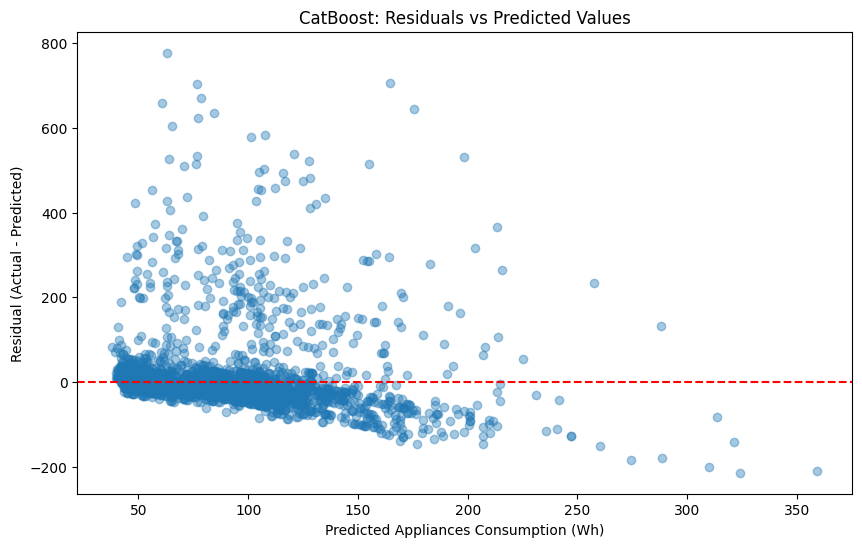

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(results['Predicted'], results['residuals'], alpha=0.4)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Appliances Consumption (Wh)')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('CatBoost: Residuals vs Predicted Values')

plt.show()

Text(0.5, 1.0, 'CatBoost: Actual vs Predicted')

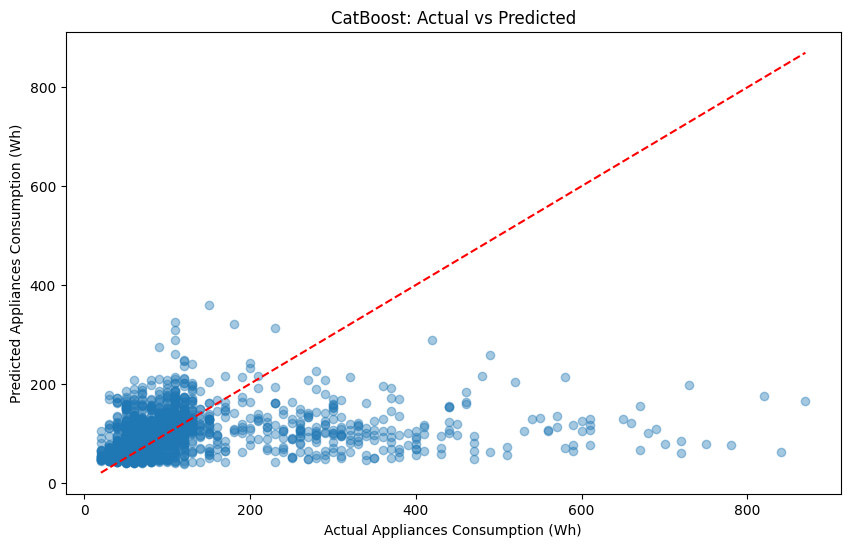

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(results['Actual'], results['Predicted'], alpha=0.4)

min_val=min(results['Actual'].min(), results['Predicted'].min())
max_val=max(results['Actual'].max(), results['Predicted'].max())

plt.plot([min_val,max_val],[min_val,max_val], 'r--')
plt.xlabel('Actual Appliances Consumption (Wh)')
plt.ylabel('Predicted Appliances Consumption (Wh)')
plt.title('CatBoost: Actual vs Predicted')

#### The residuals are centered around zero for many observations, which indicates the model captures much of the underlying pattern. However, there is a noticeable downward trend in the residuals, suggesting systematic bias, where lower values tend to be underpredicted and higher values tend to be overpredicted. There are also several large positive residuals, indicating the model struggles to predict extreme appliance consumption events. Overall, the model performs reasonably well but still shows evidence of underfitting or missing important features.